In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

### Task 1 — Explore the Dataset

In [5]:
(x_train, y_train), (x_test, y_test) = (keras.datasets.fashion_mnist.load_data())

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 15s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 1us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


In [6]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 10
0 : T-shirt/top
1 : Trouser
2 : Pullover
3 : Dress
4 : Coat
5 : Sandal
6 : Shirt
7 : Sneaker
8 : Bag
9 : Ankle boot


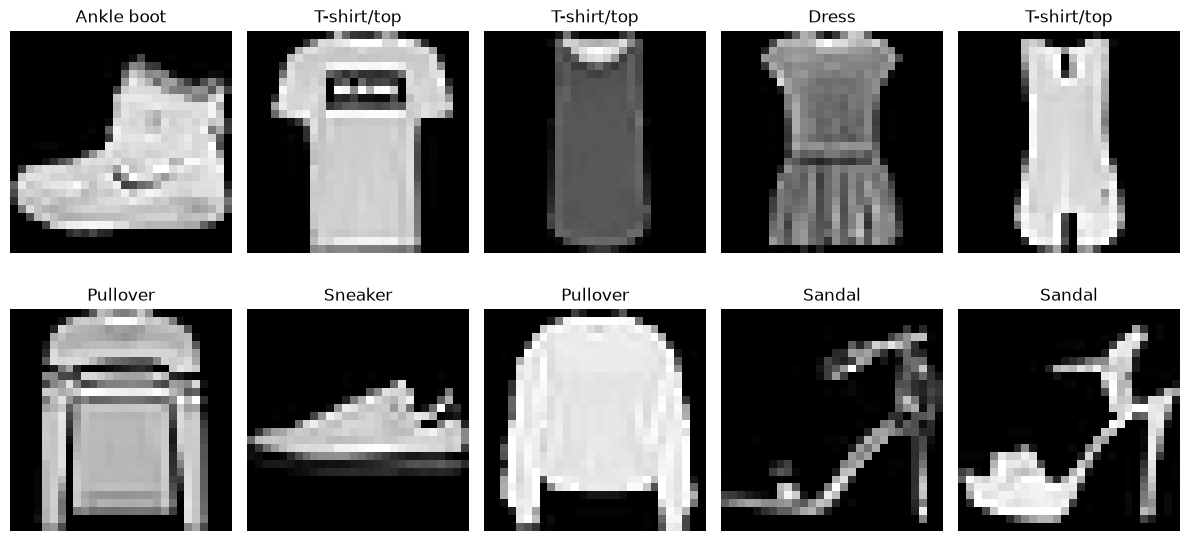

In [7]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images


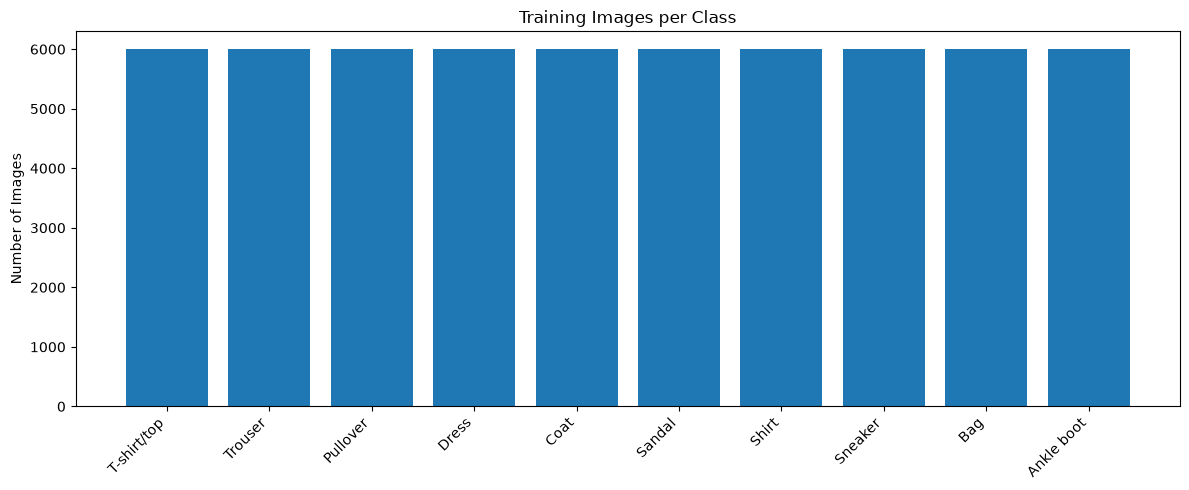

In [8]:
class_counts = np.bincount(y_train, minlength=10)

for i, count in enumerate(class_counts):
    print(f"{class_names[i]}: {count} images")

plt.figure(figsize=(12, 5))

plt.bar(class_names, class_counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Images")
plt.title("Training Images per Class")

plt.tight_layout()
plt.show()

### Normalization

In [9]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

np.random.seed(42)

indices = np.random.permutation(len(x_train))
val_size = 6000

val_indices = indices[:val_size]
train_indices = indices[val_size:]

x_val = x_train[val_indices]
y_val = y_train[val_indices]

x_train = x_train[train_indices]
y_train = y_train[train_indices]

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Testing set:", x_test.shape, y_test.shape)

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training set: (54000, 28, 28) (54000,)
Validation set: (6000, 28, 28) (6000,)
Testing set: (10000, 28, 28) (10000,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


1. Why do we normalize pixel values?

Normalization scales pixel values from 0–255 to 0–1, which helps stabilize and speed up training and improves the optimization process.

2. Is the dataset balanced?

Yes, the Fashion MNIST dataset is balanced. Each of the 10 classes contains 6,000 training images in the original training set, so all classes are equally represented.

### Task 2 — Train a Baseline Model

In [10]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(x_val, y_val)
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8113 - loss: 0.5484 - val_accuracy: 0.8315 - val_loss: 0.4898
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8515 - loss: 0.4166 - val_accuracy: 0.8622 - val_loss: 0.3995
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8634 - loss: 0.3822 - val_accuracy: 0.8637 - val_loss: 0.3849
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8709 - loss: 0.3617 - val_accuracy: 0.8657 - val_loss: 0.3759
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8780 - loss: 0.3418 - val_accuracy: 0.8677 - val_loss: 0.3654
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8801 - loss: 0.3285 - val_accuracy: 0.8680 - val_loss: 0.3717
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8846 - loss: 0.3170 - val_accuracy: 0.8702 - val_loss: 0.3646
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8868 - loss: 0.3080 - 

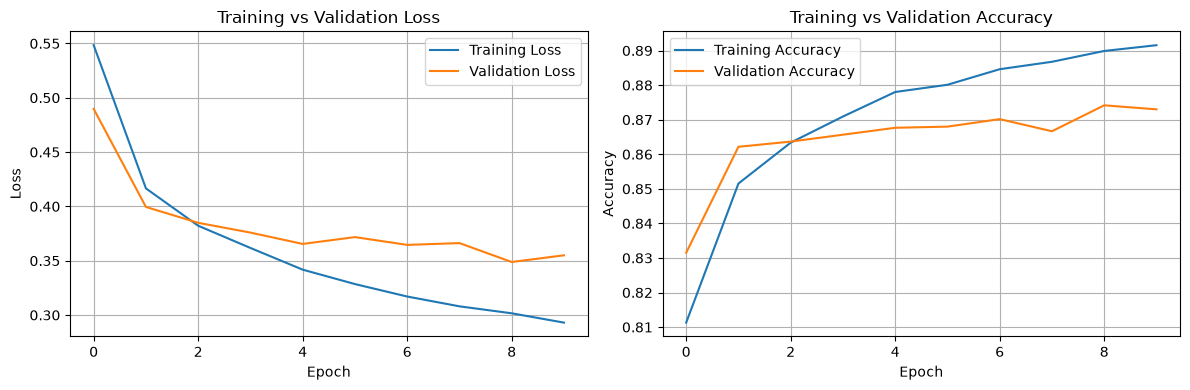

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

What is the purpose of Flatten, ReLU, and Softmax?
- Flatten: Converts the 28 × 28 image into a one-dimensional vector of 784 values.
- ReLU: Introduces non-linearity by converting negative inputs to zero, helping the network learn complex patterns.
- Softmax: Converts the output scores into probabilities across the 10 classes, with probabilities summing to 1.

### Task 3 — Analyze Predictions

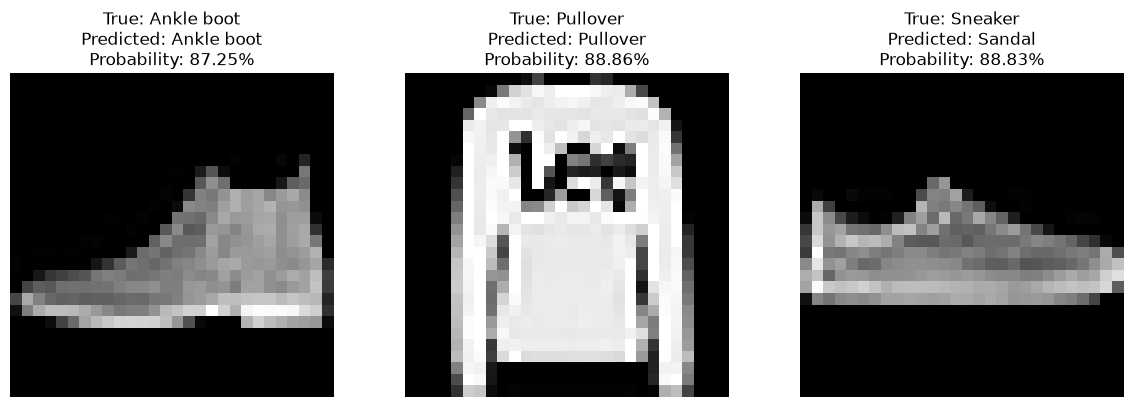

In [15]:
y_prob = model.predict(x_test, verbose=0)

y_pred = np.argmax(y_prob, axis=1)

correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

selected_indices = [
    correct_indices[0],
    correct_indices[1],
    incorrect_indices[0]
]

plt.figure(figsize=(12, 4))

for i, idx in enumerate(selected_indices):
    predicted_class = y_pred[idx]
    true_class = y_test[idx]
    confidence = y_prob[idx, predicted_class] * 100

    plt.subplot(1, 3, i + 1)
    plt.imshow(x_test[idx], cmap="gray")

    plt.title(
        f"True: {class_names[true_class]}\n"
        f"Predicted: {class_names[predicted_class]}\n"
        f"Probability: {confidence:.2f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

How does the image move through the model (forward pass)?

The image enters the input layer as a 28 × 28 matrix. The Flatten layer converts it into 784 values, the hidden Dense layer applies ReLU to learn patterns, and the output layer uses Softmax to calculate probabilities for the 10 classes. The class with the highest probability is selected as the prediction.


### Task 4 — Compare Epochs

In [16]:
import time

epoch_results = {}
epoch_histories = {}

for n_epochs in [5, 10, 20]:

    print(f"\nTraining model with {n_epochs} epochs")

    # Create a fresh model
    experiment_model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    experiment_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    experiment_history = experiment_model.fit(
        x_train,
        y_train,
        epochs=n_epochs,
        batch_size=32,
        validation_data=(x_val, y_val),
        verbose=1
    )

    elapsed_time = time.time() - start_time

    epoch_histories[n_epochs] = experiment_history

    epoch_results[n_epochs] = {
        "Best Val Accuracy": max(
            experiment_history.history["val_accuracy"]
        ),
        "Best Val Loss": min(
            experiment_history.history["val_loss"]
        ),
        "Training Time (seconds)": round(elapsed_time, 2)
    }

results_df = pd.DataFrame(epoch_results).T
results_df.index.name = "Epochs"

display(results_df)


Training model with 5 epochs
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8103 - loss: 0.5544 - val_accuracy: 0.8332 - val_loss: 0.4709
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8529 - loss: 0.4182 - val_accuracy: 0.8588 - val_loss: 0.3976
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8640 - loss: 0.3848 - val_accuracy: 0.8585 - val_loss: 0.3990
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8709 - loss: 0.3616 - val_accuracy: 0.8705 - val_loss: 0.3663
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8763 - loss: 0.3426 - val_accuracy: 0.8693 - val_loss: 0.3675

Training model with 10 epochs
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8110 - loss: 0.5511 - val_accuracy: 0.8248 - val_loss: 0.4883
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8545 - loss: 0.4160 - val_accuracy: 0.8520 - val_loss: 0.4203
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━

,Best Val Accuracy,Best Val Loss,Training Time (seconds)
Epochs,,,
5,0.870500,0.366313,36.47
10,0.877167,0.347615,76.43
20,0.882000,0.335943,144.79


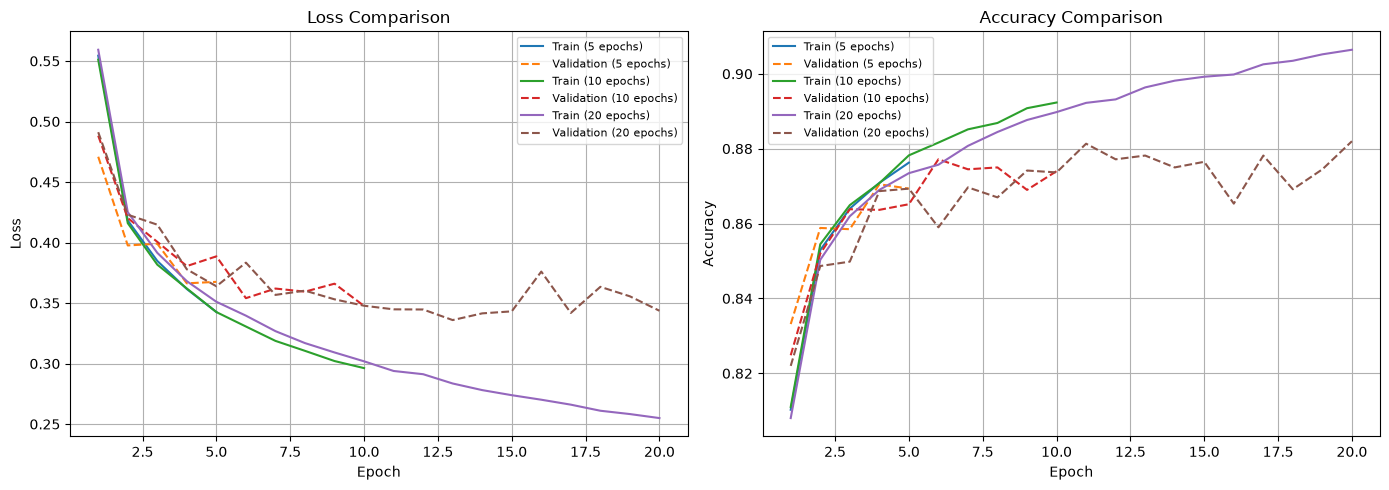

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for n_epochs, hist in epoch_histories.items():
    epochs_range = range(1, n_epochs + 1)

    axes[0].plot(
        epochs_range,
        hist.history["loss"],
        label=f"Train ({n_epochs} epochs)"
    )
    axes[0].plot(
        epochs_range,
        hist.history["val_loss"],
        linestyle="--",
        label=f"Validation ({n_epochs} epochs)"
    )


    axes[1].plot(
        epochs_range,
        hist.history["accuracy"],
        label=f"Train ({n_epochs} epochs)"
    )
    axes[1].plot(
        epochs_range,
        hist.history["val_accuracy"],
        linestyle="--",
        label=f"Validation ({n_epochs} epochs)"
    )

axes[0].set_title("Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_title("Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Task 5 — EarlyStopping Experiment

In [18]:
import time

def create_model():
    model = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


earlystop_results = {}
earlystop_histories = {}
earlystop_models = {}

# Run A: Without EarlyStopping
model_a = create_model()

start_time = time.time()

history_a = model_a.fit(
    x_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=1
)

time_a = time.time() - start_time

earlystop_models["A"] = model_a
earlystop_histories["A"] = history_a

earlystop_results["A"] = {
    "Epochs Trained": len(history_a.history["loss"]),
    "Best Val Loss": min(history_a.history["val_loss"]),
    "Final Val Accuracy": history_a.history["val_accuracy"][-1],
    "Training Time (seconds)": round(time_a, 2)
}


# Run B: EarlyStopping with patience=3
model_b = create_model()

early_stop_3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

history_b = model_b.fit(
    x_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stop_3],
    verbose=1
)

time_b = time.time() - start_time

earlystop_models["B"] = model_b
earlystop_histories["B"] = history_b

earlystop_results["B"] = {
    "Epochs Trained": len(history_b.history["loss"]),
    "Best Val Loss": min(history_b.history["val_loss"]),
    "Final Val Accuracy": model_b.evaluate(
        x_val, y_val, verbose=0
    )[1],
    "Training Time (seconds)": round(time_b, 2)
}


# Run C: EarlyStopping with patience=5
model_c = create_model()

early_stop_5 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

history_c = model_c.fit(
    x_train,
    y_train,
    epochs=40,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stop_5],
    verbose=1
)

time_c = time.time() - start_time

earlystop_models["C"] = model_c
earlystop_histories["C"] = history_c

earlystop_results["C"] = {
    "Epochs Trained": len(history_c.history["loss"]),
    "Best Val Loss": min(history_c.history["val_loss"]),
    "Final Val Accuracy": model_c.evaluate(
        x_val, y_val, verbose=0
    )[1],
    "Training Time (seconds)": round(time_c, 2)
}


earlystop_df = pd.DataFrame(earlystop_results).T
display(earlystop_df.round(4))

Epoch 1/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8074 - loss: 0.5668 - val_accuracy: 0.8435 - val_loss: 0.4507
Epoch 2/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8506 - loss: 0.4241 - val_accuracy: 0.8565 - val_loss: 0.4086
Epoch 3/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8628 - loss: 0.3886 - val_accuracy: 0.8690 - val_loss: 0.3804
Epoch 4/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8688 - loss: 0.3678 - val_accuracy: 0.8665 - val_loss: 0.3692
Epoch 5/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8754 - loss: 0.3502 - val_accuracy: 0.8677 - val_loss: 0.3702
Epoch 6/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8778 - loss: 0.3371 - val_accuracy: 0.8655 - val_loss: 0.3717
Epoch 7/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8844 - loss: 0.3263 - val_accuracy: 0.8768 - val_loss: 0.3488
Epoch 8/40
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8858 - loss: 0.3155 -

,Epochs Trained,Best Val Loss,Final Val Accuracy,Training Time (seconds)
A,40.0,0.3395,0.8763,265.94
B,12.0,0.3435,0.8745,68.20
C,15.0,0.3393,0.8767,82.50


Q1: What does patience=3 and patience=5 mean?

patience=3 allows training to continue for three consecutive epochs without improvement in validation loss before stopping. patience=5 allows five consecutive epochs without improvement.

Q2: Why might EarlyStopping help?

EarlyStopping can reduce unnecessary training time and help prevent overfitting by stopping training when validation loss stops improving. With restore_best_weights=True, the model restores the weights from the epoch with the best monitored validation loss.

### Task 6 — Hidden Neurons Experiment

In [19]:
import time

neuron_results = {}
neuron_histories = {}
neuron_models = {}

for units in [16, 32, 128]:

    print(f"\nTraining model with {units} hidden neurons")

    model_neurons = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model_neurons.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history_neurons = model_neurons.fit(
        x_train,
        y_train,
        epochs=10,
        batch_size=32,
        validation_data=(x_val, y_val),
        verbose=1
    )

    elapsed_time = time.time() - start_time

    neuron_models[units] = model_neurons
    neuron_histories[units] = history_neurons

    neuron_results[units] = {
        "Best Train Accuracy": max(
            history_neurons.history["accuracy"]
        ),
        "Best Val Accuracy": max(
            history_neurons.history["val_accuracy"]
        ),
        "Best Val Loss": min(
            history_neurons.history["val_loss"]
        ),
        "Training Time (seconds)": round(elapsed_time, 2)
    }

neuron_df = pd.DataFrame(neuron_results).T
neuron_df.index.name = "Hidden Neurons"

display(neuron_df.round(4))


Training model with 16 hidden neurons
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7929 - loss: 0.6090 - val_accuracy: 0.8392 - val_loss: 0.4666
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8493 - loss: 0.4341 - val_accuracy: 0.8512 - val_loss: 0.4130
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8586 - loss: 0.4022 - val_accuracy: 0.8617 - val_loss: 0.3974
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8657 - loss: 0.3830 - val_accuracy: 0.8597 - val_loss: 0.4079
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8686 - loss: 0.3706 - val_accuracy: 0.8650 - val_loss: 0.3828
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8725 - loss: 0.3595 - val_accuracy: 0.8673 - val_loss: 0.3764
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8741 - loss: 0.3535 - val_accuracy: 0.8683 - val_loss: 0.3722
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/st

,Best Train Accuracy,Best Val Accuracy,Best Val Loss,Training Time (seconds)
Hidden Neurons,,,,
16,0.8803,0.8733,0.3722,58.41
32,0.8920,0.8788,0.3401,60.13
128,0.9088,0.8850,0.3175,89.91


Q1: Did increasing the number of neurons always improve validation accuracy?
In this experiment, increasing the number of hidden neurons improved validation accuracy. The accuracy increased from 87.33% with 16 neurons to 87.88% with 32 neurons and 88.50% with 128 neurons. However, increasing the number of neurons does not always improve performance, as larger models may require more computation and can overfit the training data.

Q2: What is the trade-off between model capacity and computation time?
Increasing the number of hidden neurons increases the model's capacity to learn complex patterns, which may improve predictive performance. However, it also increases computational cost and training time. Therefore, the model should balance predictive performance with computational efficiency.

### Task 7 — Batch Size Experiment

In [20]:
import time

batch_results = {}
batch_histories = {}
batch_models = {}

for batch in [8, 32, 128]:
    print(f"\nTraining with batch_size = {batch}")

    model_batch = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model_batch.compile(
        optimizer=keras.optimizers.Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history_batch = model_batch.fit(
        x_train, y_train,
        epochs=10,
        batch_size=batch,
        validation_data=(x_val, y_val),
        verbose=1
    )

    elapsed_time = time.time() - start_time

    batch_models[batch] = model_batch
    batch_histories[batch] = history_batch

    epoch_times = history_batch.history.get("time", None)

    batch_results[batch] = {
        "Best Val Accuracy": max(
            history_batch.history["val_accuracy"]
        ),
        "Final Val Accuracy": history_batch.history["val_accuracy"][-1],
        "Best Val Loss": min(
            history_batch.history["val_loss"]
        ),
        "Total Time (seconds)": round(elapsed_time, 2),
        "Avg Time per Epoch (seconds)": round(
            elapsed_time / len(history_batch.history["loss"]), 2
        )
    }

batch_df = pd.DataFrame(batch_results).T
batch_df.index.name = "Batch Size"

display(batch_df.round(4))



Training with batch_size = 8
Epoch 1/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 31s 4ms/step - accuracy: 0.8213 - loss: 0.5150 - val_accuracy: 0.8492 - val_loss: 0.4147
Epoch 2/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 25s 4ms/step - accuracy: 0.8575 - loss: 0.4019 - val_accuracy: 0.8600 - val_loss: 0.3990
Epoch 3/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.8674 - loss: 0.3698 - val_accuracy: 0.8435 - val_loss: 0.4191
Epoch 4/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.8750 - loss: 0.3480 - val_accuracy: 0.8663 - val_loss: 0.3793
Epoch 5/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.8789 - loss: 0.3346 - val_accuracy: 0.8670 - val_loss: 0.3577
Epoch 6/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.8825 - loss: 0.3233 - val_accuracy: 0.8770 - val_loss: 0.3548
Epoch 7/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.8867 - loss: 0.3107 - val_accuracy: 0.8720 - val_loss: 0.3502
Epoch 8/10
6750/6750 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/ste

,Best Val Accuracy,Final Val Accuracy,Best Val Loss,Total Time (seconds),Avg Time per Epoch (seconds)
Batch Size,,,,,
8,0.8770,0.8720,0.3502,234.57,23.46
32,0.8732,0.8730,0.3493,60.53,6.05
128,0.8747,0.8747,0.3575,19.52,1.95


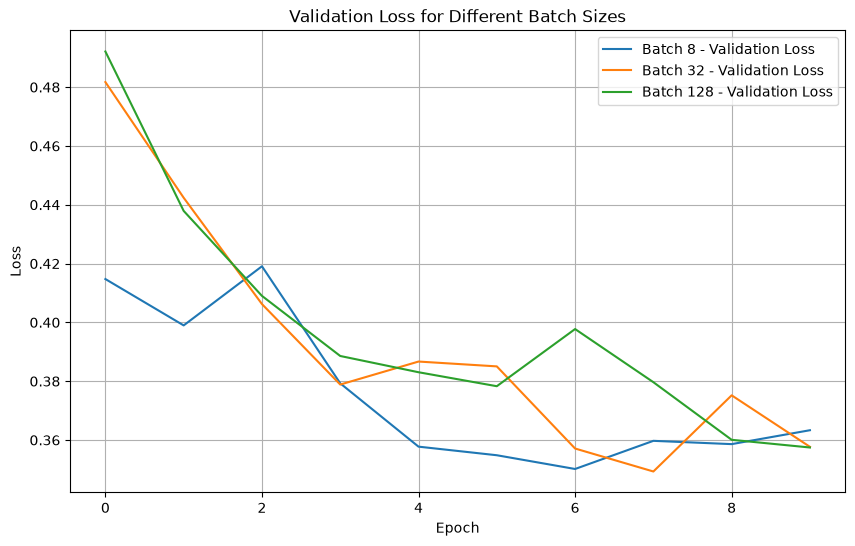

In [21]:
plt.figure(figsize=(10, 6))

for batch in [8, 32, 128]:
    plt.plot(
        batch_histories[batch].history["val_loss"],
        label=f"Batch {batch} - Validation Loss"
    )

plt.title("Validation Loss for Different Batch Sizes")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### Task 8 — Optimizer Comparison

In [22]:
import time

optimizer_configs = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD_Momentum": keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "Adam": keras.optimizers.Adam(learning_rate=0.001)
}

optimizer_histories = {}
optimizer_models = {}
optimizer_results = {}

for name, optimizer in optimizer_configs.items():
    print(f"\nTraining with {name}")

    model_opt = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model_opt.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history_opt = model_opt.fit(
        x_train, y_train,
        epochs=10,
        batch_size=32,
        validation_data=(x_val, y_val),
        verbose=1
    )

    elapsed_time = time.time() - start_time

    optimizer_models[name] = model_opt
    optimizer_histories[name] = history_opt

    optimizer_results[name] = {
        "Final Train Accuracy": history_opt.history["accuracy"][-1],
        "Final Val Accuracy": history_opt.history["val_accuracy"][-1],
        "Best Val Accuracy": max(history_opt.history["val_accuracy"]),
        "Final Train Loss": history_opt.history["loss"][-1],
        "Best Val Loss": min(history_opt.history["val_loss"]),
        "Training Time (seconds)": round(elapsed_time, 2)
    }

optimizer_df = pd.DataFrame(optimizer_results).T
optimizer_df.index.name = "Optimizer"

display(optimizer_df.round(4))



Training with SGD
Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7357 - loss: 0.8172 - val_accuracy: 0.8007 - val_loss: 0.5910
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8167 - loss: 0.5385 - val_accuracy: 0.8228 - val_loss: 0.5162
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8304 - loss: 0.4887 - val_accuracy: 0.8292 - val_loss: 0.4848
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8381 - loss: 0.4640 - val_accuracy: 0.8342 - val_loss: 0.4681
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8451 - loss: 0.4468 - val_accuracy: 0.8415 - val_loss: 0.4572
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8497 - loss: 0.4340 - val_accuracy: 0.8442 - val_loss: 0.4519
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8527 - loss: 0.4233 - val_accuracy: 0.8460 - val_loss: 0.4412
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.855

,Final Train Accuracy,Final Val Accuracy,Best Val Accuracy,Final Train Loss,Best Val Loss,Training Time (seconds)
Optimizer,,,,,,
SGD,0.8608,0.8490,0.8533,0.4009,0.4214,67.89
SGD_Momentum,0.8820,0.8617,0.8707,0.3193,0.3668,65.34
Adam,0.8923,0.8723,0.8775,0.2948,0.3464,58.46


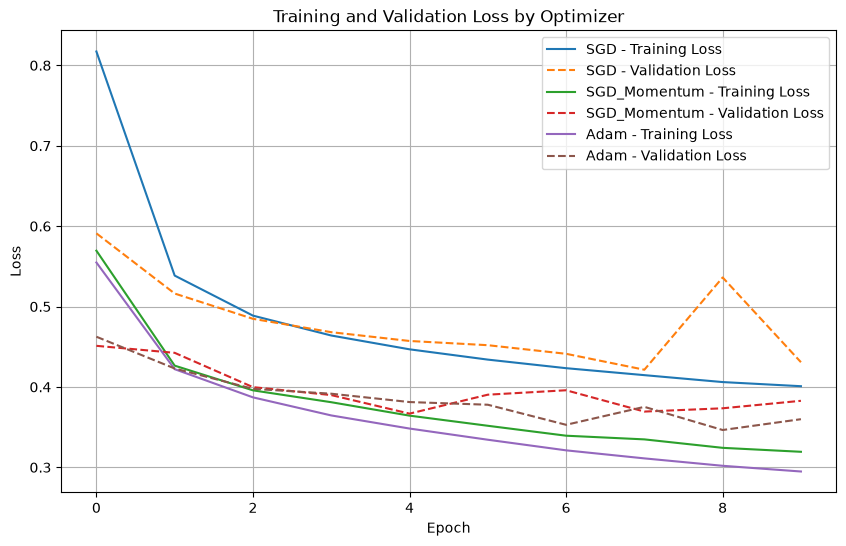

In [23]:
plt.figure(figsize=(10, 6))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["loss"],
        label=f"{name} - Training Loss"
    )
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation Loss"
    )

plt.title("Training and Validation Loss by Optimizer")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### Task 9 — Activation Function Comparison

In [24]:
activation_histories = {}
activation_models = {}
activation_results = {}

activation_histories["ReLU"] = history
activation_models["ReLU"] = model

model_tanh = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(32, activation="tanh"),
    layers.Dense(10, activation="softmax")
])

model_tanh.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()

history_tanh = model_tanh.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(x_val, y_val),
    verbose=1
)

tanh_time = time.time() - start_time

activation_histories["tanh"] = history_tanh
activation_models["tanh"] = model_tanh

activation_results["tanh"] = {
    "Final Train Accuracy": history_tanh.history["accuracy"][-1],
    "Final Val Accuracy": history_tanh.history["val_accuracy"][-1],
    "Best Val Accuracy": max(history_tanh.history["val_accuracy"]),
    "Best Val Loss": min(history_tanh.history["val_loss"]),
    "Training Time (seconds)": round(tanh_time, 2)
}

display(pd.DataFrame(activation_results).T.round(4))


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8153 - loss: 0.5362 - val_accuracy: 0.8442 - val_loss: 0.4310
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8569 - loss: 0.3982 - val_accuracy: 0.8660 - val_loss: 0.3756
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8692 - loss: 0.3652 - val_accuracy: 0.8662 - val_loss: 0.3632
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8751 - loss: 0.3445 - val_accuracy: 0.8682 - val_loss: 0.3543
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8808 - loss: 0.3303 - val_accuracy: 0.8650 - val_loss: 0.3609
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8855 - loss: 0.3176 - val_accuracy: 0.8740 - val_loss: 0.3486
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8879 - loss: 0.3088 - val_accuracy: 0.8808 - val_loss: 0.3288
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8916 - loss: 0.2987 - 

,Final Train Accuracy,Final Val Accuracy,Best Val Accuracy,Best Val Loss,Training Time (seconds)
tanh,0.8969,0.8805,0.8808,0.3288,67.02


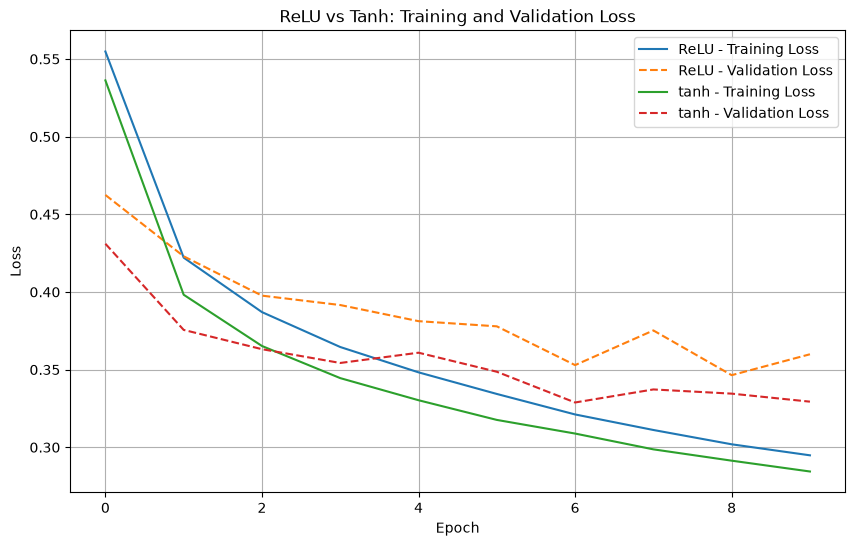

In [25]:
plt.figure(figsize=(10, 6))

for name, hist in activation_histories.items():
    plt.plot(
        hist.history["loss"],
        label=f"{name} - Training Loss"
    )
    plt.plot(
        hist.history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation Loss"
    )

plt.title("ReLU vs Tanh: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### Task 10 — Evaluate the Final Model

In [26]:
final_model = neuron_models[128]

test_loss, test_accuracy = final_model.evaluate(
    x_test, y_test, verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8793 - loss: 0.3454
Test Loss: 0.3454
Test Accuracy: 0.8793


<Figure size 1100x900 with 0 Axes>

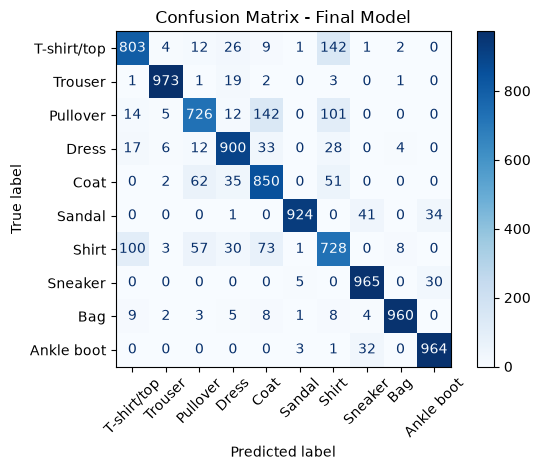

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_prob_final = final_model.predict(x_test, verbose=0)
y_pred_final = np.argmax(y_prob_final, axis=1)

cm = confusion_matrix(y_test, y_pred_final)


plt.figure(figsize=(11, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Final Model")
plt.tight_layout()
plt.show()


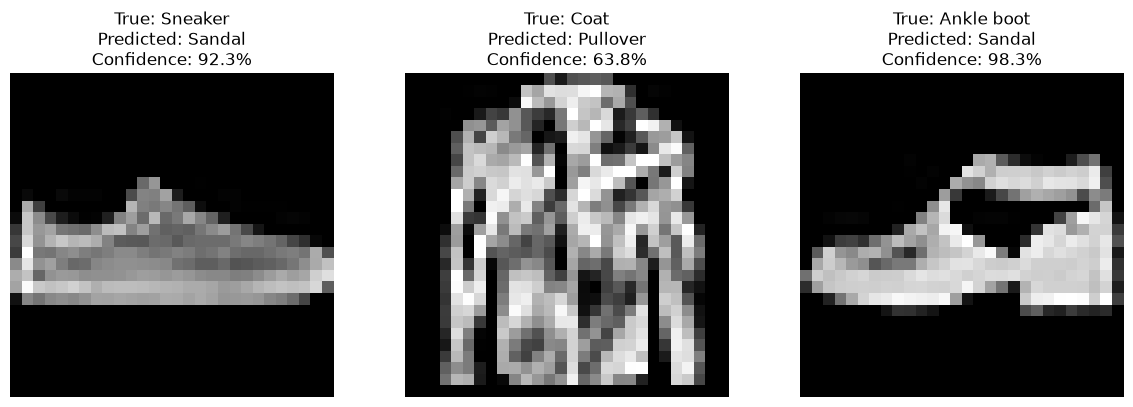

In [28]:
incorrect_indices = np.where(y_pred_final != y_test)[0]

selected_wrong = incorrect_indices[:3]

plt.figure(figsize=(12, 4))

for i, idx in enumerate(selected_wrong):
    true_label = class_names[y_test[idx]]
    predicted_label = class_names[y_pred_final[idx]]
    confidence = y_prob_final[idx, y_pred_final[idx]] * 100

    plt.subplot(1, 3, i + 1)
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {confidence:.1f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
